# Completed GPU experiment
Pramika Garg · ML4FG

Both cell-level models completed five epochs on split 101/seed 17. The entire timed
comparison took 109 minutes 6 seconds, within the three-hour limit. This notebook
reads saved artifacts; **running it does not start or resume training**.

Additive prediction has the lowest primary error. These are preliminary results
from one split, one initialization and five epochs, not the final repeated comparison.

In [1]:
from pathlib import Path
import json,sys,subprocess
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'gpu').exists(): ROOT=ROOT.parent
RESULTS=ROOT/'gpu/results/bounded_3h'
verification=subprocess.run([sys.executable,'-m','gpu.verify_results','--results',str(RESULTS)],cwd=ROOT,capture_output=True,text=True,check=True)
print(verification.stdout)


{
  "passed": true,
  "archive_files_checked": 27,
  "models": [
    {
      "prior": "depmap",
      "aggregation": "attention",
      "best_epoch": 3,
      "epochs_completed": 5,
      "pairs": 31,
      "test_mse": 0.01984661292690546,
      "additive_mse": 0.010981933353155317,
      "pairs_better_than_additive": 6
    },
    {
      "prior": "native",
      "aggregation": "sum",
      "best_epoch": 3,
      "epochs_completed": 5,
      "pairs": 31,
      "test_mse": 0.01374732825486127,
      "additive_mse": 0.010981933353155317,
      "pairs_better_than_additive": 7
    }
  ],
  "total_wall_seconds": 6546.059376239777,
  "total_wall_minutes": 109.10098960399628,
  "under_three_hours": true,
  "verification": "Independent NumPy errors on saved predictions, all three scoring subsets; validation-only selection; matched settings; artifact hashes",
  "limitation": "One pair partition, one initialization, five epochs; conditional pair-level results"
}



In [2]:
summary=pd.read_csv(RESULTS/'summary.csv')
primary=summary.query("subset=='top1000'").copy()
rows=[dict(method='Additive',mse=primary.additive_mse.iloc[0],pairs_better_than_additive='-')]
for prior,label in [('native','GEARS'),('depmap','GEARS + DepMap + attention')]:
    row=primary.query('prior==@prior').iloc[0]
    rows.append(dict(method=label,mse=row.mean_mse,pairs_better_than_additive=f'{round(row.fraction_pairs_better*31)}/31'))
display(pd.DataFrame(rows))
display(primary[['prior','mean_mse','paired_improvement','ci_low','ci_high','status']])


,method,mse,pairs_better_than_additive
0,Additive,0.010982,-
1,GEARS,0.013747,7/31
2,GEARS + DepMap + attention,0.019847,6/31


,prior,mean_mse,paired_improvement,ci_low,ci_high,status
1,depmap,0.019847,-0.008865,-0.013373,-0.004293,preliminary_single_split
4,native,0.013747,-0.002765,-0.005258,-0.000051,preliminary_single_split


## Fixed training settings and selection
Both models use 64 hidden units, all 19,264 genes, 67,592 training cells, batch 32,
FP16, the same split/initialization, original fourth-power/direction loss and schedule.
Both selected epoch 3 using validation error, then scored the same 31 held-out pairs.
The extension changes prior and aggregation together, so this comparison cannot
isolate their individual contributions. The additive predictor also wins on the
all-gene and top 20-DE scoring subsets.

In [3]:
runs=[]
for name in ['bounded_native_sum_split101_seed17','bounded_depmap_attention_split101_seed17']:
    result=json.loads((RESULTS/name/'result.json').read_text())
    result['method']=name
    runs.append(result)
display(pd.DataFrame(runs)[['method','state','epochs_completed','best_epoch','validation_mse','test_mse','elapsed_seconds','skipped_amp_updates']])
display(summary[['prior','subset','mean_mse','additive_mse','paired_improvement']])


,method,state,epochs_completed,best_epoch,validation_mse,test_mse,elapsed_seconds,skipped_amp_updates
0,bounded_native_sum_split101_seed17,complete,5,3,0.013639,0.013747,3264.694630,6
1,bounded_depmap_attention_split101_seed17,complete,5,3,0.018870,0.019847,3243.571169,5


,prior,subset,mean_mse,additive_mse,paired_improvement
0,depmap,all,0.002112,0.001226,-0.000886
1,depmap,top1000,0.019847,0.010982,-0.008865
2,depmap,top20DE_scoring_only,0.156632,0.036802,-0.119829
3,native,all,0.001936,0.001226,-0.000710
4,native,top1000,0.013747,0.010982,-0.002765
5,native,top20DE_scoring_only,0.103772,0.036802,-0.066970


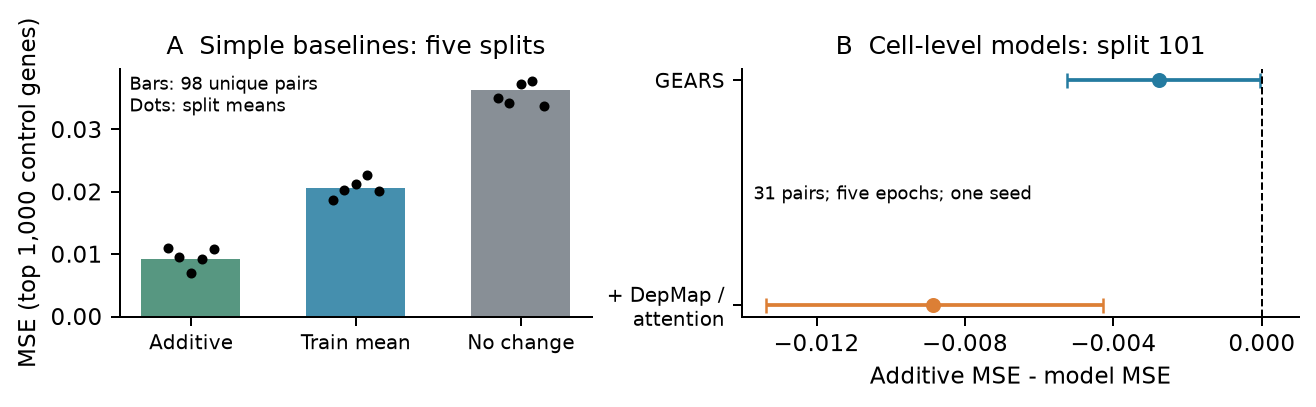

In [4]:
display(Image(filename=str(ROOT/'gpu/figures/03_performance.png')))

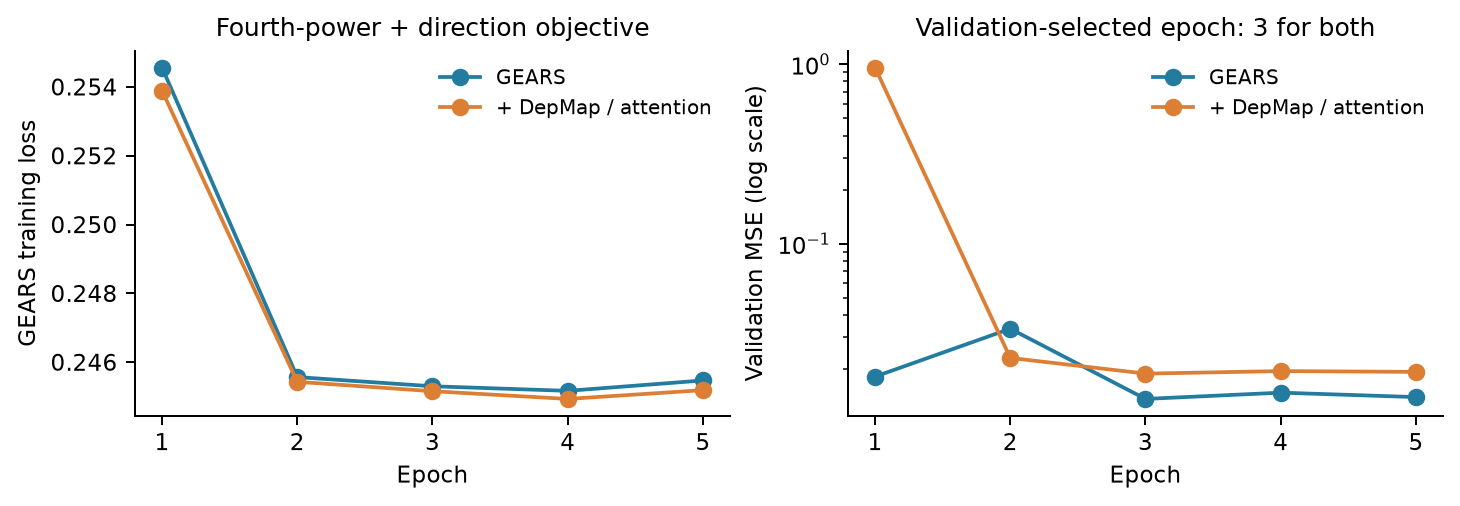

In [5]:
display(Image(filename=str(ROOT/'gpu/figures/04_training.png')))

## Interpretation and limits
The neural configurations did not beat additivity here. The extension's validation
error was unstable early in training, so its negative result is not evidence that
all embeddings or attention are ineffective. Additional splits, seeds, schedules
and separate prior/aggregation ablations remain future work. The upstream graph's
batch dependence is documented in the protocol; this is not a reproduction of every
published GEARS number. Pair-bootstrap intervals are conditional on these fitted
models and do not capture split/seed or gene-sharing dependence.

A few FP16 updates were skipped by the gradient scaler, as recorded in the run
metadata. This is handled scaler behavior, not a failed fit. CUDA attention warns
that GPU arithmetic may not be bitwise deterministic. No further training was
performed after these artifacts were collected.